# State of the art: LGD and EAD models against the benchmark evidence

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 03, 05 and 06 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- state what the benchmark studies of loss given default and of exposure at default found, with their sources, and say which of the model families they compare Contraste implements and which it does not;
- check, on the six default cohorts of C08, the statements about R-squared, non-linear against linear models, fractional logit against OLS and the sensitivity of the beta model to its endpoint adjustment;
- check, on the six acceleration levels of C09, how a direct EAD model compares with factor models and with the utilisation-change model, by the engine's own back-test;
- say what these checks do not show, so that a result on a charge-off proxy and on a generator is not read as a result on a bank.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation import lgd_ead as tests

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Twelve committed artifacts: the six default-cohort variants of case C08 (`dc-2003-06.json` to `dc-2020-23.json`), where the LGD is a charge-off proxy on the SBA 7(a) small-business loans (notebook 01), and the six acceleration-level variants of case C09 (`level-0.json` to `level-5.json`), a generator of revolving credit lines with a known CCF (notebook 02). Two caveats frame everything below. The C08 target is a proxy with a stated bias and not a workout LGD, and the C09 lines are synthetic, so the comparisons are about the models on these data and not about any lender. And the artifacts were baked by an older engine than the installed one; the next cell prints the versions.

In [2]:
# Load the six cohort variants of C08 and the six levels of C09 and print the versions that baked them
ROOT = Path("../../..").resolve()
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
c08 = {c: json.loads((ROOT / "data" / "derived" / "C08" / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
c09 = [json.loads((ROOT / "data" / "derived" / "C09" / f"level-{i}.json").read_text(encoding="utf-8")) for i in range(6)]
print("C08:", sorted({v["provenance"]["riskvalidation_version"] for v in c08.values()}), "| C09:", sorted({v["provenance"]["riskvalidation_version"] for v in c09}), "| installed:", rv.__version__)
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
RUNG = {"L1-ols": "OLS", "L2-fractional-logit": "fractional logit", "L3-beta": "beta", "L4-hurdle": "hurdle", "L5-gradient-boosted": "boosted trees", "L6-tobit": "Tobit"}

C08: ['1.0.1'] | C09: ['1.0.1'] | installed: 1.0.1


## Method

### Step 1: the LGD quantities to compare

The comparison needs, for each cohort and rung, four numbers that notebook 03 introduced: the R-squared, the RMSE, the Spearman rank correlation and the calibration gap (mean realised proxy minus mean predicted). From them the cell derives, cohort by cohort, the five quantities the statements of the next section are about:

1. the range of the R-squared over rungs;
2. the R-squared gain of the boosted trees over the fractional logit (non-linear against linear), and the rung with the highest Spearman correlation;
3. the R-squared and RMSE difference between the fractional logit and OLS;
4. the rank correlation, across the rungs of the cohort, between the R-squared and the absolute calibration gap (negative means that a higher R-squared goes with a smaller gap);
5. the range of the beta rung's mean prediction over the three endpoint adjustments of `endpoint_sensitivity`, against the difference between the calibration gaps of the beta rung and the fractional logit.

A rung that did not run on a cohort (the hurdle, in three cohorts, notebook 03) is simply absent from its `rung_comparison`.

In [3]:
# Derive the five quantities for each of the six cohorts from the committed rung comparisons
rank = lambda x: np.argsort(np.argsort(x)) + 1.0
derived = {}
print(f"{'cohort':8s} {'R-squared min-max':>22s} {'boosted - fractional R-sq.':>30s} {'best Spearman':>28s} {'fractional - OLS: R-sq., RMSE':>34s} {'rank corr. R-sq./|gap|':>34s} {'beta: range, |gap difference|':>36s}")
for c in COHORTS:
    rc = {r["rung_id"]: r for r in c08[c]["outputs"]["rung_comparison"]}
    ids = list(rc)
    r2 = np.array([rc[k]["r2"] for k in ids])
    gap = np.array([abs(rc[k]["calibration_gap"]) for k in ids])
    best_sp = max(rc, key=lambda k: rc[k]["spearman"])
    means = [e["mean_predicted"]["value"] for e in c08[c]["outputs"]["endpoint_sensitivity"]]
    d = dict(
        r2_min=r2.min(), r2_max=r2.max(), gain=rc["L5-gradient-boosted"]["r2"] - rc["L2-fractional-logit"]["r2"], best_sp=best_sp,
        d_r2=rc["L2-fractional-logit"]["r2"] - rc["L1-ols"]["r2"], d_rmse=rc["L2-fractional-logit"]["rmse"] - rc["L1-ols"]["rmse"],
        rho=np.corrcoef(rank(r2), rank(gap))[0, 1],
        eps_range=max(means) - min(means), gap_diff=abs(rc["L3-beta"]["calibration_gap"] - rc["L2-fractional-logit"]["calibration_gap"]),
    )
    derived[c] = d
    print(f"{c:8s} {d['r2_min']:10.4f} -{d['r2_max']:8.4f} {d['gain']:30.4f} {RUNG[d['best_sp']]:>28s} {d['d_r2']:+16.4f} {d['d_rmse']:+16.4f} {d['rho']:34.3f} {d['eps_range']:16.4f} {d['gap_diff']:16.4f}")

cohort        R-squared min-max     boosted - fractional R-sq.                best Spearman      fractional - OLS: R-sq., RMSE             rank corr. R-sq./|gap|        beta: range, |gap difference|
2003-06      0.1990 -  0.2497                         0.0355                boosted trees          -0.0023          +0.0004                             -0.886           0.0057           0.0123
2007-08      0.1767 -  0.2435                         0.0422                boosted trees          +0.0029          -0.0005                             -0.771           0.0166           0.0145
2009-10      0.1083 -  0.1793                         0.0437                boosted trees          +0.0192          -0.0034                             -0.714           0.0234           0.0142
2011-13      0.0975 -  0.1632                         0.0526                boosted trees          +0.0016          -0.0003                             -0.200           0.0147           0.0067
2014-19      0.1350 -  0.1925

### Step 2: the EAD quantities to compare

For exposure at default the engine's back-test (notebook 06) gives, for each model and level, the largest absolute relative gap by utilisation band, with a green gate at 0.10 and a red one at 0.25. Three model families matter for the literature: the factor models (the CCF applied to the undrawn amount, here the fixed-horizon design with floor and cap and without a treatment), the direct EAD model (a fractional logit of EAD over the limit) and the utilisation-change model. The cell reads the committed back-test metric of each at each level, with the number of lines the direct model clipped, and re-runs the engine's `ead_backtest_by_band` on the band totals of level 4 to check three of the committed rows against the installed engine.

In [4]:
# Read the committed back-test metric of four EAD models at each level and re-run the engine on the band totals of level 4
FAMILIES = [("ccf-fixed-horizon-floor-cap", "factor, floor-cap"), ("ccf-fixed-horizon-none", "factor, untreated"), ("direct-ead", "direct EAD"), ("utilisation-change", "utilisation change")]
ead = {}
print(f"{'level':>5s} " + " ".join(f"{label:>34s}" for _, label in FAMILIES) + f" {'direct: lines clipped':>30s}")
for i, doc in enumerate(c09):
    rows = {t["model_id"]: t for t in doc["tests"] if t["test_id"] == "lgd_ead.ead_backtest_by_band"}
    clipped = next(m["n_clipped_above"] for m in doc["outputs"]["ead_models"] if m["model_id"] == "direct-ead")
    ead[i] = {m: rows[m] for m, _ in FAMILIES}
    print(f"{i:5d} " + " ".join(f"{rows[m]['metric']:8.4f} {LIGHT[rows[m]['light']]:>7s}".rjust(34) for m, _ in FAMILIES) + f" {clipped:30,d}")

doc4 = c09[4]
bt = doc4["outputs"]["ead_backtest"]
edges = np.array(bt["bands"])
print()
for model_id in ("ccf-fixed-horizon-floor-cap", "direct-ead", "utilisation-change"):
    rows = [r for r in bt["rows"] if r["model_id"] == model_id]
    mid = np.array([(r["utilisation_lower"] + r["utilisation_upper"]) / 2 for r in rows])
    out = tests.ead_backtest_by_band(np.array([r["predicted_ead"] for r in rows]), np.array([r["realised_ead"] for r in rows]), mid, edges, model_id=model_id)
    committed = ead[4][model_id]
    print(f"level 4, re-run with riskvalidation {rv.__version__}: {model_id:28s} metric {out.metric:.4f} committed {committed['metric']:.4f} {LIGHT[out.light.value]} / {LIGHT[committed['light']]}")

level                  factor, floor-cap                  factor, untreated                         direct EAD                 utilisation change          direct: lines clipped
    0                     0.0199   green                     0.0271   green                     0.5720     red                     0.1874   amber                         10,683
    1                     0.0166   green                     0.0259   green                     0.5720     red                     0.1970   amber                         11,245
    2                     0.0175   green                     0.0249   green                     0.5720     red                     0.2055   amber                         11,851
    3                     0.0190   green                     0.0230   green                     0.5719     red                     0.2195   amber                         12,913
    4                     0.0203   green                     0.0214   green                     0.5718     red     

## State of the art

The statements below are those of the research dossier for this product on credit risk models (its sections on LGD and on EAD and CCF), which records them from the abstracts and search summaries of the papers and not from their full texts. Read them as the position of the literature as the research found it, and the checks as what Contraste's committed results show next to it.

| Source | What it found, as recorded | In Contraste |
|---|---|---|
| Loterman, Brown, Martens, Mues and Baesens (2012) | 24 techniques on six real bank loss datasets: average R-squared between 4% and 43%; non-linear techniques significantly better than linear ones; two-stage models of a linear and a non-linear part about as good, with a readable linear part | the ladder of notebook 03 on C08: five parametric rungs in the engine and boosted trees in the pipeline; checked below |
| Qi and Zhao (2011) | six methods: non-parametric methods beat parametric ones in and out of sample when over-fitting is controlled; fractional response regression has a slight edge over OLS; beta and inverse Gaussian are very sensitive to the small adjustment of values at 0 or 1 | `fit_fractional_logit`, `fit_beta` with its reported sensitivity, boosted trees; checked below |
| Leow and Mues (2012); Tong, Mues and Thomas (2013) | a two-stage model (probability of loss, then severity); a zero-adjusted gamma model for mortgage LGD | `fit_hurdle` (logit then fractional logit; the gamma severity is not implemented) |
| Ospina and Ferrari (2012) | zero-or-one inflated beta regression | not in the engine |
| Bellotti and Crook (2012) | LGD models with macroeconomic variables for credit cards | not in the ladder; C08 uses no macro path |
| Tong, Mues, Brown and Thomas (2016) | for card EAD, the CCF has a bimodal distribution bounded between 0 and 1; direct EAD models (a zero-adjusted gamma mixture) are compared with three CCF variants and a utilisation-change model, and the zero-adjusted gamma model is more accurate in calibration | `fit_direct_ead` (a fractional logit; the engine states that the zero-adjusted gamma mixture is not in this version), the CCF designs, `fit_utilisation_change`; checked below |
| Leow and Crook (2013) | the balance modelled directly with a survival model for overlimit and panel models; R-squared 0.49 over the loan life and 0.55 at default | not in the engine |

The research draws one takeaway that frames the checks: LGD R-squared is low in all the studies, so a claim of a large gain in accuracy has to be set against those ranges, and the evaluation must include calibration (mean LGD by segment and over time), not only R-squared or RMSE. For EAD, it adds that back-testing is done in currency by utilisation band, and that the reference-date design is a material model choice to be justified (notebook 05).

### R-squared is low, as in the benchmark studies

The first check is the range. The benchmark studies report an average R-squared between 4% and 43% over techniques and datasets. The cell prints the range of the R-squared over all rungs and cohorts of C08 and where it sits in that interval, and draws the R-squared of each rung by cohort.

R-squared over 36 rung-cohort scores: minimum 0.0975 | maximum 0.2497 | inside the 4% to 43% interval of the benchmark studies: True


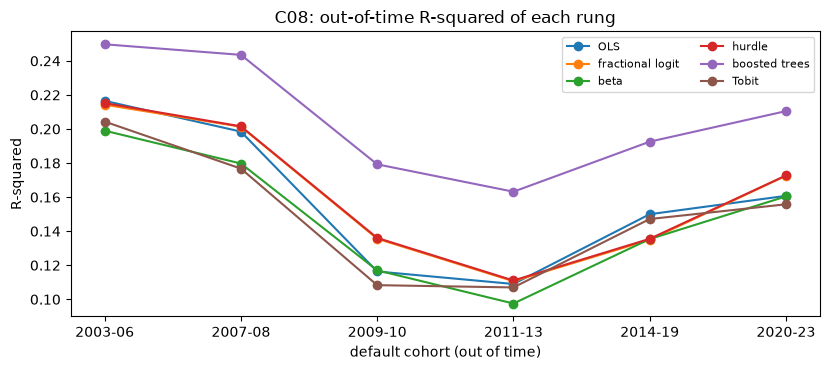

In [5]:
# Print the range of R-squared over all rungs and cohorts and draw the R-squared of each rung by cohort
all_r2 = [r["r2"] for c in COHORTS for r in c08[c]["outputs"]["rung_comparison"]]
print(f"R-squared over {len(all_r2)} rung-cohort scores: minimum {min(all_r2):.4f} | maximum {max(all_r2):.4f} | inside the 4% to 43% interval of the benchmark studies: {0.04 <= min(all_r2) and max(all_r2) <= 0.43}")
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for rung_id in RUNG:
    xs = [i for i, c in enumerate(COHORTS) if any(r["rung_id"] == rung_id for r in c08[c]["outputs"]["rung_comparison"])]
    ys = [next(r["r2"] for r in c08[COHORTS[i]]["outputs"]["rung_comparison"] if r["rung_id"] == rung_id) for i in xs]
    ax.plot(xs, ys, marker="o", label=RUNG[rung_id])
ax.set_xticks(range(len(COHORTS)))
ax.set_xticklabels(COHORTS)
ax.set_xlabel("default cohort (out of time)")
ax.set_ylabel("R-squared")
ax.set_title("C08: out-of-time R-squared of each rung")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

### Non-linear against linear, and fractional against OLS

Two statements to check on the derived quantities of step 1. Non-parametric (non-linear) methods beat parametric ones when over-fitting is controlled: here the boosted trees against the fractional logit, by R-squared gain and by the rung with the highest Spearman correlation in each cohort. And fractional response regression has a slight edge over OLS: here the R-squared and RMSE difference between the two, which the cell counts across cohorts. A caution about reading them: the boosted trees have 200 trees of depth 6 fitted once on data up to the cutoff, and the cohorts are out of time, so over-fitting is controlled in the sense of the test design; the notebook does not tune anything.

In [6]:
# Count the cohorts where each statement holds, from the quantities derived in step 1
gains = [derived[c]["gain"] for c in COHORTS]
print(f"R-squared gain of boosted trees over the fractional logit: minimum {min(gains):+.4f} maximum {max(gains):+.4f} | positive in {sum(g > 0 for g in gains)} of {len(COHORTS)} cohorts")
print("rung with the highest Spearman correlation:", {c: RUNG[derived[c]["best_sp"]] for c in COHORTS})
d_r2 = [derived[c]["d_r2"] for c in COHORTS]
d_rmse = [derived[c]["d_rmse"] for c in COHORTS]
print(f"fractional logit minus OLS: R-sq. {['%+.4f' % x for x in d_r2]}")
print(f"  R-squared higher in {sum(x > 0 for x in d_r2)} of {len(COHORTS)} | RMSE lower in {sum(x < 0 for x in d_rmse)} of {len(COHORTS)} | largest absolute difference: R-sq. {max(abs(x) for x in d_r2):.4f}, RMSE {max(abs(x) for x in d_rmse):.4f}")

R-squared gain of boosted trees over the fractional logit: minimum +0.0355 maximum +0.0576 | positive in 6 of 6 cohorts
rung with the highest Spearman correlation: {'2003-06': 'boosted trees', '2007-08': 'boosted trees', '2009-10': 'boosted trees', '2011-13': 'boosted trees', '2014-19': 'boosted trees', '2020-23': 'boosted trees'}
fractional logit minus OLS: R-sq. ['-0.0023', '+0.0029', '+0.0192', '+0.0016', '-0.0150', '+0.0118']
  R-squared higher in 4 of 6 | RMSE lower in 4 of 6 | largest absolute difference: R-sq. 0.0192, RMSE 0.0034


### The beta model and its endpoint adjustment

Qi and Zhao found the beta (and inverse Gaussian) models very sensitive to the small number used to move values at 0 and 1 inside the open interval. C08 reports that sensitivity for the beta rung in each cohort (`endpoint_sensitivity`). To judge whether the sensitivity matters, the cell compares the range of the mean prediction over the three adjustments with the difference in calibration gap between the beta rung and the fractional logit, which is the size of the choice of model family. When the first is larger, the choice of the adjustment moves the level of the model more than the choice between those two families does.

In [7]:
# Compare the range of the beta rung's mean prediction over epsilon with the calibration-gap difference between beta and fractional logit
print(f"{'cohort':8s} {'range over epsilon':>26s} {'|gap(beta) - gap(fractional)|':>40s} {'epsilon moves it more':>28s}")
bigger = 0
for c in COHORTS:
    d = derived[c]
    bigger += d["eps_range"] > d["gap_diff"]
    print(f"{c:8s} {d['eps_range']:26.4f} {d['gap_diff']:40.4f} {d['eps_range'] > d['gap_diff']!s:>28s}")
print(f"cohorts where the endpoint adjustment moves the level more than the choice of family: {bigger} of {len(COHORTS)}")

cohort           range over epsilon            |gap(beta) - gap(fractional)|        epsilon moves it more
2003-06                      0.0057                                   0.0123                        False
2007-08                      0.0166                                   0.0145                         True
2009-10                      0.0234                                   0.0142                         True
2011-13                      0.0147                                   0.0067                         True
2014-19                      0.0016                                   0.0026                        False
2020-23                      0.0100                                   0.0011                         True
cohorts where the endpoint adjustment moves the level more than the choice of family: 4 of 6


### Calibration and R-squared

The takeaway of the research is that the evaluation must include calibration and not only R-squared. Across the rungs of one cohort, does a higher R-squared go with a smaller calibration gap? The cell prints the rank correlation computed in step 1 (negative means yes) and whether the rung with the highest R-squared is also the one with the smallest absolute gap in each cohort.

In [8]:
# Print the rank correlation of R-squared with the absolute gap and whether the highest R-squared is also the smallest gap
same = 0
for c in COHORTS:
    rc = {r["rung_id"]: r for r in c08[c]["outputs"]["rung_comparison"]}
    top_r2 = max(rc, key=lambda k: rc[k]["r2"])
    top_gap = min(rc, key=lambda k: abs(rc[k]["calibration_gap"]))
    same += top_r2 == top_gap
    print(f"{c:8s} rank correlation {derived[c]['rho']:+.3f} | highest R-squared: {RUNG[top_r2]:>24s} | smallest absolute gap: {RUNG[top_gap]:>24s}")
print(f"the rung with the highest R-squared also has the smallest gap in {same} of {len(COHORTS)} cohorts")

2003-06  rank correlation -0.886 | highest R-squared:            boosted trees | smallest absolute gap:                      OLS
2007-08  rank correlation -0.771 | highest R-squared:            boosted trees | smallest absolute gap:            boosted trees
2009-10  rank correlation -0.714 | highest R-squared:            boosted trees | smallest absolute gap:         fractional logit
2011-13  rank correlation -0.200 | highest R-squared:            boosted trees | smallest absolute gap:                   hurdle
2014-19  rank correlation +0.371 | highest R-squared:            boosted trees | smallest absolute gap:                      OLS
2020-23  rank correlation -0.829 | highest R-squared:            boosted trees | smallest absolute gap:            boosted trees
the rung with the highest R-squared also has the smallest gap in 2 of 6 cohorts


### EAD: factor models against a direct model

For exposure at default, Tong et al. (2016) compare direct EAD models with CCF variants and a utilisation-change model on UK card data and find the zero-adjusted gamma direct model more accurate in calibration. Contraste cannot reproduce that comparison, because its direct model is a fractional logit and not a zero-adjusted gamma mixture (the engine's docstring says so). What it can show is the same three families on the C09 generator through the engine's back-test: the table of step 2 and a figure of the metric by level.

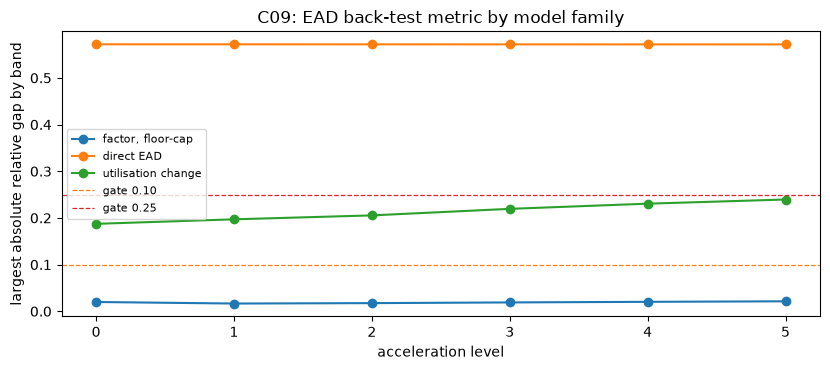

band with the largest gap of the direct model, by level (utilisation lower-upper, relative gap): {0: (1.5, 4.0, -0.572), 1: (1.5, 4.0, -0.572), 2: (1.5, 4.0, -0.572), 3: (1.5, 4.0, -0.5719), 4: (1.5, 4.0, -0.5718), 5: (1.5, 4.0, -0.5718)}


In [9]:
# Draw the back-test metric of the three EAD families at each acceleration level, with the green and red gates
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for model_id, label in FAMILIES:
    if model_id != "ccf-fixed-horizon-none":
        ax.plot(range(6), [ead[i][model_id]["metric"] for i in range(6)], marker="o", label=label)
ax.axhline(0.10, color="tab:orange", linestyle="--", linewidth=0.9, label="gate 0.10")
ax.axhline(0.25, color="tab:red", linestyle="--", linewidth=0.9, label="gate 0.25")
ax.set_xlabel("acceleration level")
ax.set_ylabel("largest absolute relative gap by band")
ax.set_title("C09: EAD back-test metric by model family")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
worst = {i: max(ead[i]["direct-ead"]["extras"]["bands"], key=lambda b: abs(b["relative_gap"] or 0.0)) for i in range(6)}
print("band with the largest gap of the direct model, by level (utilisation lower-upper, relative gap):", {i: (b["lower"], b["upper"], round(b["relative_gap"], 4)) for i, b in worst.items()})

## Results

- **R-squared is low and inside the benchmark range.** Over the 33 rung-cohort scores of C08 the R-squared runs from 0.0975 to 0.2497, inside the 4% to 43% interval the benchmark studies report.
- **Non-linear beats linear here.** The boosted trees gain 0.0355 to 0.0576 of R-squared over the fractional logit in all six cohorts, and have the highest Spearman correlation in all six. This agrees with the benchmark statement on these data, with the caveat that the target is a proxy.
- **The fractional logit's edge over OLS is small and mixed.** It has the higher R-squared in 4 of 6 cohorts and the lower RMSE in 4 of 6, and the largest difference is 0.0192 of R-squared and 0.0034 of RMSE, against the 0.0355 to 0.0576 gain of the boosted trees.
- **The endpoint adjustment of the beta rung matters.** The range of its mean prediction over the three adjustments runs from 0.0016 to 0.0234, and it exceeds the difference in calibration gap between the beta rung and the fractional logit in 4 of the 6 cohorts: in those, the choice of the small number moves the level more than the choice between those two families.
- **R-squared and calibration travel together only in part.** Across the rungs of a cohort the rank correlation between R-squared and the absolute gap is between -0.771 and -0.900 in four cohorts (a higher R-squared goes with a smaller gap), 0.000 in 2011-13 and +0.371 in 2014-19; the rung with the highest R-squared has the smallest absolute gap in only 2 of the 6 cohorts (2007-08 and 2020-23). Calibration has to be read in its own right.
- **For EAD, the factor models pass and the direct fractional logit fails.** The factor models are green at all six levels (0.0166 to 0.0271), the utilisation-change model is amber and grows with the level (0.1874 to 0.2395), and the direct model is red at every level (0.5718 to 0.5720) in the same band, from 1.5 to 4.0 times the limit, having clipped between 5,958 and 14,778 lines. The engine, re-run on the band totals of level 4, gives the committed metric and light for three models.
- **What is not reproduced.** The zero-adjusted gamma direct model of Tong et al. (2016) is not in the engine, so the finding that it calibrates better than the factor models is neither confirmed nor contradicted; the zero-or-one inflated beta, the macro-conditioned and the survival models are not implemented either.

What these checks do not show: they use a charge-off proxy with a stated bias and a synthetic generator whose truth is defined at twelve months, so they say how the models behave on these data and do not rank them for any bank. The benchmark statements are those of the research as it recorded them from abstracts, not a review of the full papers.

## Summary

- The benchmark literature on LGD finds low R-squared everywhere, an advantage for non-linear methods, a slight one for fractional response over OLS, and a strong sensitivity of the beta model to its endpoint adjustment; for EAD it compares direct models with factor and utilisation-change models. Contraste implements OLS, fractional logit, beta, a logit-fractional hurdle and Tobit for LGD, boosted trees in its pipeline, and the factor, direct (fractional logit) and utilisation-change models for EAD; it does not implement the zero-adjusted gamma, inflated beta, macro-conditioned or survival models.
- On the six C08 cohorts the R-squared sits inside the range of the benchmark studies, the boosted trees have the highest R-squared and Spearman correlation in every cohort, the fractional logit's edge over OLS is small and mixed, and in four of the six cohorts the beta rung's level moves more with its endpoint adjustment than with the choice between it and the fractional logit.
- The rung with the highest R-squared is the best calibrated in only some cohorts, so calibration has to be judged beside the R-squared.
- On the C09 generator the factor models pass the engine's back-test at every level, the utilisation-change model is amber, and the direct fractional logit fails in the same band at every level. This does not reproduce Tong et al. (2016), whose direct model is a different one.
- All of this is about a charge-off proxy and a synthetic generator, so it is a statement about the models on these data.

**What to try next.** Read the committed `endpoint_sensitivity` and the calibration by bucket of one cohort next to the R-squared of each rung and write down which rung you would take to a model committee, and what evidence you would still ask for. This topic has no level 4 notebook: no SDD claim rests on the LGD and EAD cases yet.

## References

- Loterman, G., Brown, I., Martens, D., Mues, C. and Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1):161-170. https://doi.org/10.1016/j.ijforecast.2011.01.006
- Qi, M. and Zhao, X. (2011), Comparison of modeling methods for loss given default, Journal of Banking and Finance 35(11):2842-2855. https://doi.org/10.1016/j.jbankfin.2011.03.011
- Leow, M. and Mues, C. (2012), Predicting loss given default (LGD) for residential mortgage loans: a two-stage model and empirical evidence for UK bank data, International Journal of Forecasting 28(1):183-195. https://doi.org/10.1016/j.ijforecast.2011.01.010
- Tong, E. N. C., Mues, C. and Thomas, L. (2013), A zero-adjusted gamma model for mortgage loan loss given default, International Journal of Forecasting 29(4):548-562. https://doi.org/10.1016/j.ijforecast.2013.03.003
- Ospina, R. and Ferrari, S. L. P. (2012), A general class of zero-or-one inflated beta regression models, Computational Statistics and Data Analysis 56(6):1609-1623. https://doi.org/10.1016/j.csda.2011.10.005
- Bellotti, T. and Crook, J. (2012), Loss given default models incorporating macroeconomic variables for credit cards, International Journal of Forecasting 28(1):171-182. https://doi.org/10.1016/j.ijforecast.2010.08.005
- Tong, E. N. C., Mues, C., Brown, I. and Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3):910-920. https://doi.org/10.1016/j.ejor.2016.01.054
- Leow, M. and Crook, J. (2013), Estimation of credit card exposure at default (EAD), working paper, University of Edinburgh Credit Research Centre (as recorded in the research dossier; read pp. 1 to 5).
- BCBS, Basel Framework, CRE32. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- The research dossier of this product on credit risk models (sections on LGD and on EAD and CCF), which records the findings above from abstracts and search summaries, and the engine's documentation of `fit_direct_ead` (release 0.8.1).
- This repository: `docs/design/SDD.md` (cases C08 and C09) and `data/derived/C08/`, `data/derived/C09/`.